### Задание

1. Выбрать QA датасет (https://huggingface.co/datasets). 
2. На выбранном датасете обучить модель https://huggingface.co/intfloat/multilingual-e5-small с помощью этого кода.
3. Переписать код под актуальную версию sentence-transformers.
4. Сравнить результаты

In [ ]:
# pip install transformers==4.45.2 
# pip install sentence-transformers==3.1.1

In [ ]:
pip install sentence-transformers

In [1]:
# import pickle
# from random import shuffle

# from datasets import load_dataset
# from sentence_transformers import InputExample

import os
import random

import numpy as np
import torch

from datasets import load_dataset, Dataset

from sentence_transformers import (
    SentenceTransformer,
    SentenceTransformerTrainer,
    SentenceTransformerTrainingArguments,
    losses,
    util,
)

/home/guseva-n@ad.speechpro.com/dsp/venv/lib/python3.11/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]
/home/guseva-n@ad.speechpro.com/dsp/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/guseva-n@ad.speechpro.com/dsp/venv/lib/python3.11/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]
/tmp/ipykernel_32528/3334920017

In [2]:
import torch

device = 'mps' if torch.backends.mps.is_built() else 'cuda' if torch.cuda.is_available() else 'cpu'

print(device)

cuda


In [3]:
# from sentence_transformers import SentenceTransformer, models


# def raw_bi_encoder():
#     word_embedding_model = models.Transformer('cointegrated/rubert-tiny2', max_seq_length=256)
#     pooling_model = models.Pooling(word_embedding_model.get_word_embedding_dimension())

#     bi_encoder = SentenceTransformer(
#         modules=[word_embedding_model, pooling_model],
#         device=device,
#     )

#     return bi_encoder

def raw_bi_encoder(model_name: str, max_seq_length: int = 512):
    model = SentenceTransformer(
        model_name,
        device=device,
    )

    model.max_seq_length = max_seq_length

    return model

In [4]:
# bi_encoder = raw_bi_encoder()

# print(bi_encoder)
MODEL_NAME = "intfloat/multilingual-e5-small"
bi_encoder = raw_bi_encoder(MODEL_NAME, max_seq_length=512)

print(bi_encoder)

Loading weights: 100%|██████████| 199/199 [00:03<00:00, 54.51it/s]


SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'BertModel'})
  (1): Pooling({'embedding_dimension': 384, 'pooling_mode': 'mean', 'include_prompt': True})
  (2): Normalize({'module_input_name': 'sentence_embedding', 'module_output_name': 'sentence_embedding'})
)


## Служебные функции для работы с данными

In [5]:
DATASET_ID = "kuznetsoffandrey/sberquad"
SEED = 42

# Префиксы для multilingual-e5-small.
# для rubert нужны пустые префиксы: "" и "".
QUERY_PREFIX = "query: "
PASSAGE_PREFIX = "passage: "

# Простой кэш исходного датасета в памяти, чтобы не грузить его каждый раз.
_RAW_DATASET_CACHE = {}

In [6]:
def shrink_repeated_samples(
        queries,
        docs,
        labels,
):
    docs_was = set()
    qs = []
    ds = []
    ls = []
    for i in range(len(queries)):
        q, d, l = queries[i], docs[i], labels[i]
        if d in docs_was:
            continue
        qs.append(q)
        ds.append(d)
        ls.append(l)
        docs_was.add(d)

    return qs, ds, ls


# def trainval_shuffled_data(from_file=True):
#     datafile = 'trainval.pkl'

#     if from_file:
#         with open(datafile, 'rb') as f:
#             data = pickle.load(f)
#         return data

#     good, bad = load_trainval_samples()
#     data = good + bad
#     shuffle(data)

#     with open(datafile, 'wb') as f:
#         pickle.dump(data, f)

#     return data
def trainval_shuffled_data(from_file=None):
    """
    Возвращает перемешанные обучающие пары:
        (question, context, label)

    from_file оставлен для совместимости со старыми вызовами,
    но больше не используется.
    """
    good, bad = load_trainval_samples()
    data = good + bad

    random.Random(SEED).shuffle(data)

    return data

# def test_shuffled_data(from_file=True):
#     datafile = 'test.pkl'

#     if from_file:
#         with open(datafile, 'rb') as f:
#             data = pickle.load(f)
#         return data

#     good, bad = load_test_samples()
#     data = good + bad

#     with open(datafile, 'wb') as f:
#         pickle.dump(data, f)

#     return data
def test_shuffled_data(from_file=None):
    """
    Возвращает перемешанные тестовые пары:
        (question, context, label)

    from_file оставлен для совместимости со старыми вызовами,
    но больше не используется.
    """
    good, bad = load_test_samples()
    data = good + bad

    random.Random(SEED + 1).shuffle(data)

    return data

# def trainval_examples():
#     data = trainval_shuffled_data(from_file=True)

#     trainval = []
#     for question, document, cos in data:
#         trainval.append(
#             InputExample(texts=[question, document], label=cos)
#         )

#     return trainval
def trainval_examples(from_file=None):
    """
    Старая функция возвращала InputExample(...).

    Новая версия возвращает обычный список словарей:
        [{"anchor": ..., "positive": ..., "score": ...}, ...]
    """
    data = trainval_shuffled_data()

    return pairs_to_rows(
        pairs=data,
        query_prefix=QUERY_PREFIX,
        passage_prefix=PASSAGE_PREFIX,
    )

def load_test_samples():
    _, _, test = _load_sberquad_dataset()

    questions = test['question'].tolist()
    contexts = test['context'].tolist()

    return _inflate_with_negative_samples(
        questions=questions,
        contexts=contexts,
    )


def load_trainval_samples():
    train, val, _ = _load_sberquad_dataset()

    questions = train['question'].tolist() + val['question'].tolist()
    contexts = train['context'].tolist() + val['context'].tolist()

    return _inflate_with_negative_samples(
        questions=questions,
        contexts=contexts,
    )


def _inflate_with_negative_samples(
        questions,
        contexts,
        delta=30,  # in sberquad dataset same contexts are close
):
    good_q_c_cos = list(zip(questions, contexts, [1.0] * len(questions)))

    bad_q_c_cos = []
    n = len(good_q_c_cos)
    for i in range(n):
        cur_q, cur_c, _ = good_q_c_cos[i]
        next_q, next_c, _ = good_q_c_cos[(i + delta) % n]
        if next_c != cur_c:
            bad_q_c_cos.append((cur_q, next_c, 0.0))

    return good_q_c_cos, bad_q_c_cos


# def _load_raw_sberquad_dataset(from_file=True):
#     sberquad = 'sberquad.pkl'
#     if from_file:
#         with open(sberquad, 'rb') as f:
#             df = pickle.load(f)
#     else:
#         df = load_dataset('sberquad')
#         with open(sberquad, 'wb') as f:
#             pickle.dump(df, f)

#     return df
def _load_raw_sberquad_dataset(from_file=None, dataset_id=DATASET_ID):
    """
    Загружаем датасет и кэшируем его в памяти.

    from_file оставлен в сигнатуре для совместимости со старым кодом,
    но больше не используется: pickle-файлы мы не читаем.
    """
    if dataset_id not in _RAW_DATASET_CACHE:
        _RAW_DATASET_CACHE[dataset_id] = load_dataset(dataset_id)

    return _RAW_DATASET_CACHE[dataset_id]

# def _load_sberquad_dataset():
#     df = _load_raw_sberquad_dataset()
#     train = df['train'].to_pandas()
#     validation = df['validation'].to_pandas()
#     test = df['test'].to_pandas()

#     return train, validation, test
def _load_sberquad_dataset():
    """
    Возвращаем train, validation, test в виде pandas DataFrame,
    чтобы старые функции ниже могли работать без изменений.
    """
    ds = _load_raw_sberquad_dataset()

    if "train" not in ds:
        raise ValueError(f"В датасете {DATASET_ID} нет сплита train.")

    train_split = ds["train"]

    if "validation" in ds:
        validation_split = ds["validation"]
    else:
        validation_split = train_split

    if "test" in ds:
        test_split = ds["test"]
    elif "validation" in ds:
        test_split = ds["validation"]
    else:
        test_split = train_split

    train = train_split.to_pandas()

    if "validation" in ds:
        validation = validation_split.to_pandas()
    else:
        validation = train.copy()

    if "test" in ds:
        test = test_split.to_pandas()
    elif "validation" in ds:
        test = validation.copy()
    else:
        test = train.copy()

    return train, validation, test

def pairs_to_rows(pairs, query_prefix=QUERY_PREFIX, passage_prefix=PASSAGE_PREFIX):
    """
    Превращает:
        [(question, context, label), ...]

    в список словарей:
        {
            "anchor": "...",
            "positive": "...",
            "score": float
        }

    Такой формат понимают современные loss functions в sentence-transformers.
    """
    rows = []

    for question, context, score in pairs:
        rows.append(
            {
                "anchor": f"{query_prefix}{question}",
                "positive": f"{passage_prefix}{context}",
                "score": float(score),
            }
        )

    return rows

def trainval_dataset(from_file=None):
    """
    Готовит Hugging Face Dataset из обучающих пар.
    """
    rows = trainval_examples()

    return Dataset.from_list(rows)

# Метрики близости без дообучения на trainval

In [7]:
# trainval = trainval_shuffled_data(from_file=True)

# n_samples = 1000
# # questions, document_contexts, coss = zip(*trainval[:n_samples])
# questions, document_contexts, coss = zip(*trainval)

trainval = trainval_shuffled_data()

n_samples = 1000

if len(trainval) > n_samples:
    trainval_sample = random.Random(SEED).sample(trainval, n_samples)
else:
    trainval_sample = trainval

questions_raw, document_contexts_raw, coss = zip(*trainval_sample)

# e5-small требует query/passage, rubert-tiny2 — нет.
if "multilingual-e5" in MODEL_NAME:
    questions = [QUERY_PREFIX + q for q in questions_raw]
    document_contexts = [PASSAGE_PREFIX + d for d in document_contexts_raw]
else:
    questions = questions_raw
    document_contexts = document_contexts_raw

In [8]:
# evaluator = evaluation.EmbeddingSimilarityEvaluator(questions, document_contexts, coss)

In [9]:
# bi_encoder.evaluate(evaluator)

from sentence_transformers import evaluation

evaluator = evaluation.EmbeddingSimilarityEvaluator(
    questions,
    document_contexts,
    coss,
)

evaluator(bi_encoder)

/tmp/ipykernel_32528/3565600120.py:3: DeprecationWarning: Importing from 'sentence_transformers.evaluation' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.evaluation' instead.
  from sentence_transformers import evaluation


{'pearson_cosine': 0.9152786941445872, 'spearman_cosine': 0.8628457645117781}

# Метрики близости без дообучения на test

In [10]:
# n_test_samples = 1000
# test = test_shuffled_data(from_file=True)
# test_questions, test_document_contexts, test_coss = zip(*test[:n_test_samples])

In [11]:
# evaluator = evaluation.EmbeddingSimilarityEvaluator(test_questions, test_document_contexts, test_coss)

In [12]:
# bi_encoder = raw_bi_encoder()

In [13]:
# bi_encoder.evaluate(evaluator)
MAX_LEN = 512

n_test_samples = 1000

test = test_shuffled_data()

test_sample = test[:n_test_samples]

test_questions_raw, test_document_contexts_raw, test_coss = zip(*test_sample)

# Для multilingual-e5-small добавляем query/passage.
# Для rubert-tiny2 оставляем без префиксов.
if "multilingual-e5" in MODEL_NAME:
    test_questions = [QUERY_PREFIX + q for q in test_questions_raw]
    test_document_contexts = [PASSAGE_PREFIX + d for d in test_document_contexts_raw]
else:
    test_questions = test_questions_raw
    test_document_contexts = test_document_contexts_raw


evaluator_test = evaluation.EmbeddingSimilarityEvaluator(
    test_questions,
    test_document_contexts,
    test_coss,
)


# Отдельная baseline-модель, которую потом НЕ нужно обучать
baseline_model = raw_bi_encoder(
    MODEL_NAME,
    max_seq_length=MAX_LEN,
)

baseline_model.eval()

baseline_test_metrics = evaluator_test(baseline_model)

baseline_test_metrics

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3833.21it/s]


{'pearson_cosine': 0.9201645294546714, 'spearman_cosine': 0.8646678652730023}

# Дообучение

In [14]:
# # trainval_examples = trainval_examples()[:n_samples]
# trainval_examples = trainval_examples()
# print(trainval_examples[0].__dict__)

In [15]:
# from torch.utils.data import DataLoader

# trainval_dataloader_set = DataLoader(trainval_examples, shuffle=True, batch_size=32,
#                                      collate_fn=bi_encoder.smart_batching_collate)

In [16]:
# from sentence_transformers import losses

# trainval_loss_set = losses.CosineSimilarityLoss(bi_encoder)

In [17]:
# trainval_loss_set

In [18]:
# (query_batch, context_batch), labels = next(iter(trainval_dataloader_set))
# query_batch['input_ids'].shape, context_batch['input_ids'].shape, labels.shape

In [19]:
# bi_encoder.fit(
#     train_objectives=[(trainval_dataloader_set, trainval_loss_set)],
#     output_path='qa/results',
#     epochs=5,
#     evaluator=evaluator,
# )

In [20]:
import random
from datasets import Dataset


def prepare_mnrl_dataset(
    max_pairs: int = 50_000,
    seed: int = 42,
):
    """
    Готовит dataset для MultipleNegativesRankingLoss.

    MNRL ожидает positive-пары:
        anchor = query
        positive = passage

    Негативные примеры loss возьмет автоматически из текущего батча.
    """
    # Берем train + validation пары
    data = trainval_shuffled_data()

    # Оставляем только positive QA-пары
    positive_pairs = [
        (q, d)
        for q, d, label in data
        if float(label) > 0.5
    ]

    random.Random(seed).shuffle(positive_pairs)

    # Для лабораторного запуска можно ограничить размер
    if len(positive_pairs) > max_pairs:
        positive_pairs = positive_pairs[:max_pairs]

    # Формируем строки для sentence-transformers
    rows = []

    for q, d in positive_pairs:
        rows.append(
            {
                "anchor": f"{QUERY_PREFIX}{q}",
                "positive": f"{PASSAGE_PREFIX}{d}",
            }
        )

    return Dataset.from_list(rows)

In [21]:
from sentence_transformers import (
    SentenceTransformerTrainer,
    SentenceTransformerTrainingArguments,
    losses,
)

OUTPUT_DIR = "results/e5_sberquad_finetuned_mnrl"

EPOCHS = 1
TRAIN_BATCH_SIZE = 16
GRAD_ACC_STEPS = 1
LEARNING_RATE = 5e-5

# Fine-tuned модель создаем отдельно от baseline_model
fine_tuned_model = raw_bi_encoder(
    MODEL_NAME,
    max_seq_length=MAX_LEN,
)

# Для совместимости со старыми ячейками можно сделать алиас,
# но trainer лучше запускать именно от fine_tuned_model.
bi_encoder = fine_tuned_model

# Готовим dataset только с positive-парами

train_dataset = prepare_mnrl_dataset(
    max_pairs=50_000,
    seed=SEED,
)

print("MNRL train dataset size:", len(train_dataset))
print("First example:")
print(train_dataset[0])


# Retrieval-oriented loss

train_loss = losses.MultipleNegativesRankingLoss(fine_tuned_model)

# Training arguments

training_args = SentenceTransformerTrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACC_STEPS,
    learning_rate=LEARNING_RATE,
    warmup_ratio=0.1,
    logging_steps=20,
    save_strategy="no",
    fp16=False,
    bf16=False,
    report_to=[],
    seed=SEED,
    remove_unused_columns=False,
    dataloader_num_workers=0,
)


trainer = SentenceTransformerTrainer(
    model=fine_tuned_model,
    args=training_args,
    train_dataset=train_dataset,
    loss=train_loss,
)


trainer.train()

fine_tuned_model.save_pretrained(OUTPUT_DIR)

print(f"Model saved to: {OUTPUT_DIR}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3651.34it/s]
The `warmup_ratio` argument is deprecated in Transformers v5+, and will also be removed from Sentence Transformers once support for Transformers v4 is dropped. Since you're using Transformers v5+, please use `warmup_steps` (as a float) to specify the warmup ratio instead.


MNRL train dataset size: 50000
First example:
{'anchor': 'query: Что представляет собой семязачаток?', 'positive': 'passage: Семязача́ток, или семяпо́чка (лат. ovulum) — образование у семенных растений, из которого (обычно после оплодотворения) развивается семя. Представляет собой женский спорангий (мегаспорангий) семенных растений. У покрытосеменных растений семяпочка расположена в полости завязи, у голосеменных — на поверхности семенных чешуек в женских шишках. В центральной части семяпочки (нуцеллусе) формируются в результате мейоза материнской клетки спор четыре мегаспоры, затем три из них гибнут, а из одной мегаспоры формируется женский гаметофит. У цветковых он называется зародышевый мешок, у голосеменных его иногда называют эндосперм, так как в зрелом семени в нём запасаются питательные вещества. Снаружи семяпочка прикреплена семяножкой к плаценте.'}


[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 0, 'pad_token_id': 1}.


Step,Training Loss
20,1.016661
40,0.615211
60,0.233638
80,0.104123
100,0.061064
120,0.150430
140,0.097775
160,0.052741
180,0.048796
200,0.040715


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.15it/s]


Model saved to: results/e5_sberquad_finetuned_mnrl


In [22]:
fine_tuned_test_metrics = evaluator_test(bi_encoder)

print("Baseline:")
print(baseline_test_metrics)

print()
print("Fine-tuned:")
print(fine_tuned_test_metrics)

Baseline:
{'pearson_cosine': 0.9201645294546714, 'spearman_cosine': 0.8646678652730023}

Fine-tuned:
{'pearson_cosine': 0.9427875917313348, 'spearman_cosine': 0.8648895749820467}


# Загрузка чекпоинта

In [23]:
# from sentence_transformers import SentenceTransformer

# finetuned_bi_encoder = SentenceTransformer('qa/results')

In [24]:
# finetuned_bi_encoder.evaluate(evaluator)

In [25]:
from sentence_transformers import SentenceTransformer

# Если переменная OUTPUT_DIR уже определена, используем её.
# Иначе ставим путь по умолчанию, который мы использовали при обучении.
OUTPUT_DIR = globals().get("OUTPUT_DIR", "results/e5_sberquad_finetuned")
DEVICE = globals().get("DEVICE", "cpu")
MAX_LEN = globals().get("MAX_LEN", 512)

finetuned_bi_encoder = SentenceTransformer(
    OUTPUT_DIR,
    device=DEVICE,
)

finetuned_bi_encoder.max_seq_length = MAX_LEN

loaded_fine_tuned_test_metrics = evaluator_test(finetuned_bi_encoder)

loaded_fine_tuned_test_metrics

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4424.75it/s]


{'pearson_cosine': 0.9427875938725375, 'spearman_cosine': 0.8648895749820467}

# Расчёт метрик

In [26]:
# data = test_shuffled_data(from_file=True)

In [27]:
# n_test_samples = 1000
# queries, docs, labels = zip(*data[:n_test_samples])

In [28]:
# print('docs count before shrinking: ', len(docs))

In [29]:
# docs = list(set(docs))

In [30]:
# print('docs count without duplicates: ', len(docs))

In [31]:
# doc_embs = finetuned_bi_encoder.encode(
#     docs,
#     convert_to_tensor=True,
#     show_progress_bar=True,
# )

In [32]:
# query_embs = finetuned_bi_encoder.encode(
#     queries,
#     convert_to_tensor=True,
#     show_progress_bar=True,
# )

In [33]:
# from sentence_transformers import util

In [34]:
# cos_sim_score = util.semantic_search(query_embs, doc_embs, top_k=3)

In [35]:
# for_first_query = cos_sim_score[0]
# print(for_first_query)

In [36]:
# print('Question: ', queries[0])
# print()
# for no, ir in enumerate(cos_sim_score[0]):
#     corpus_id = ir["corpus_id"]
#     print('corpus id: ', corpus_id)
#     print(f'Document {no + 1}: Cosine Similarity is {ir["score"]:.3f}:\n\n{docs[corpus_id]}')
#     print()

In [37]:
# data = test_shuffled_data(from_file=True)
# n_test_samples = 1000
# queries, docs, labels = zip(*data[:n_test_samples])

# queries, docs, labels = shrink_repeated_samples(
#     queries=queries,
#     docs=docs,
#     labels=labels,
# )
# print(len(docs))

In [38]:
from sentence_transformers import util

model_for_retrieval = finetuned_bi_encoder

def encode_with_prefix(model, texts, prefix):
    """
    Кодирование текстов с префиксом.

    Для multilingual-e5-small prefix должен быть:
        query:
        passage:

    Для rubert-tiny2 prefix должен быть пустой:
        ""
    """
    texts = [prefix + str(text) for text in texts]

    embs = model.encode(
        texts,
        convert_to_tensor=True,
        device=DEVICE,
        normalize_embeddings=True,
        show_progress_bar=False,
    )

    return embs


# Готовим тестовые пары
test = test_shuffled_data()

n_test_samples = 1000
test_sample = test[:n_test_samples]

queries, docs, labels = zip(*test_sample)

print("docs count before shrinking:", len(docs))

# shrink_repeated_samples должен вызываться ДО encode.
# Именно он убирает дубликаты документов и сохраняет alignment:
# queries[i] <-> docs[i]
queries, docs, labels = shrink_repeated_samples(
    queries=queries,
    docs=docs,
    labels=labels,
)

print("docs count after shrinking:", len(docs))
print("queries count after shrinking:", len(queries))


# Для multilingual-e5-small используем query/passage
if "multilingual-e5" in MODEL_NAME:
    query_prefix = QUERY_PREFIX
    doc_prefix = PASSAGE_PREFIX
else:
    query_prefix = ""
    doc_prefix = ""


query_embs = encode_with_prefix(
    model=model_for_retrieval,
    texts=queries,
    prefix=query_prefix,
)

doc_embs = encode_with_prefix(
    model=model_for_retrieval,
    texts=docs,
    prefix=doc_prefix,
)


# Визуализация top-k для первого вопроса
top_k_vis = min(3, len(docs))

cos_sim_score = util.semantic_search(
    query_embs,
    doc_embs,
    top_k=top_k_vis,
)

print()
print("Example query:", queries[0])
print()

for no, ir in enumerate(cos_sim_score[0]):
    corpus_id = int(ir["corpus_id"])
    score = float(ir["score"])

    print(f"Document {no + 1}: corpus_id={corpus_id}, cosine={score:.3f}")
    print()
    print(docs[corpus_id])
    print()

docs count before shrinking: 1000
docs count after shrinking: 886
queries count after shrinking: 886

Example query: На каких линиях ось пути и линия трассы совпадают?

Document 1: corpus_id=20, cosine=0.385

Варианты строительства дороги в обход Байкала рассматривались ещё в 1881 году. Южный маршрут представлялся более сложным, в то же время казался предпочтительнее как более обжитой, поэтому выбор остановился на нём. Строительство трассы возглавил в 1899 году инженер Б. У. Савримович. При длине пути всего 260 км пришлось построить 39 тоннелей, 47 предохранительных галерей, 14 км подпорных стен, многочисленные виадуки, волнорезы, мосты и трубы. Объём земляных работ составил 70 тыс. кубометров на км пути. Для устройства выемок в скалах было использовано 2 400 т взрывчатки. Несмотря на перечисленные трудности, регулярное движение поездов началось на год раньше запланированного срока, в 1905 году.

Document 2: corpus_id=495, cosine=0.358

Летом 1896 года под руководством инженера А. Н. П

# Получение предсказаний модели и меток

In [39]:
# doc_embs = finetuned_bi_encoder.encode(
#     docs,
#     convert_to_tensor=True,
#     show_progress_bar=True,
# )

In [40]:
# query_embs = finetuned_bi_encoder.encode(
#     queries,
#     convert_to_tensor=True,
#     show_progress_bar=True,
# )

In [41]:
# cos_scores = util.semantic_search(query_embs, doc_embs, top_k=100)

In [42]:
# print(len(cos_scores))

In [43]:
# print(cos_scores[0][:5])

In [44]:
# top_k = 5

In [45]:
# print('Question: ', queries[0])
# print()
# for no, ir in enumerate(cos_scores[0][:top_k]):
#     corpus_id = ir["corpus_id"]
#     print('corpus id: ', corpus_id)
#     print(f'Document {no + 1}: Cosine Similarity is {ir["score"]:.3f}:\n\n{docs[corpus_id]}')
#     print()

In [46]:
# print(docs[582])

In [47]:
# n = len(queries)
# print(n)

In [48]:
# queries и docs уже должны быть подготовлены через shrink_repeated_samples(...),
# чтобы queries[i] соответствовал docs[i].
n_docs = len(docs)
n_queries = len(queries)

print("queries count:", n_queries)
print("docs count:", n_docs)

top_k_scores = min(100, n_docs)
top_k_vis = min(5, n_docs)


doc_embs = encode_with_prefix(
    model=model_for_retrieval,
    texts=docs,
    prefix=doc_prefix,
)

query_embs = encode_with_prefix(
    model=model_for_retrieval,
    texts=queries,
    prefix=query_prefix,
)


cos_scores = util.semantic_search(
    query_embs,
    doc_embs,
    top_k=top_k_scores,
)


print()
print("Number of scored queries:", len(cos_scores))
print("First query top-5:", cos_scores[0][:5])


print()
print("Example query:", queries[0])
print()

for no, ir in enumerate(cos_scores[0][:top_k_vis]):
    corpus_id = int(ir["corpus_id"])
    score = float(ir["score"])

    print(f"Document {no + 1}: corpus_id={corpus_id}, cosine={score:.3f}")
    print()
    print(docs[corpus_id])
    print()


# Старая проверка docs[582] была небезопасной.
# Оставим её с проверкой границ, если хочется что-то посмотреть.
example_doc_index = 582

if len(docs) > example_doc_index:
    print("Example document by fixed index:")
    print(docs[example_doc_index])
else:
    print(
        f"В shrunk docs только {len(docs)} документов, "
        f"индекс {example_doc_index} недоступен."
    )


queries count: 886
docs count: 886

Number of scored queries: 886
First query top-5: [{'corpus_id': 20, 'score': 0.38494545221328735}, {'corpus_id': 495, 'score': 0.3580409586429596}, {'corpus_id': 454, 'score': 0.353666752576828}, {'corpus_id': 694, 'score': 0.3536550998687744}, {'corpus_id': 423, 'score': 0.33196020126342773}]

Example query: На каких линиях ось пути и линия трассы совпадают?

Document 1: corpus_id=20, cosine=0.385

Варианты строительства дороги в обход Байкала рассматривались ещё в 1881 году. Южный маршрут представлялся более сложным, в то же время казался предпочтительнее как более обжитой, поэтому выбор остановился на нём. Строительство трассы возглавил в 1899 году инженер Б. У. Савримович. При длине пути всего 260 км пришлось построить 39 тоннелей, 47 предохранительных галерей, 14 км подпорных стен, многочисленные виадуки, волнорезы, мосты и трубы. Объём земляных работ составил 70 тыс. кубометров на км пути. Для устройства выемок в скалах было использовано 2 400 

In [49]:
def build_target_mask_for_i(i, n):
    target_mask = [False] * n
    target_mask[i] = True

    return target_mask

In [50]:
def build_pred_mask_for_i(
        cos_scores,
        i,
        n,
):
    pred_mask = [0.0] * n
    qi_scores = cos_scores[i]

    for docid_score in qi_scores:
        doc_id = docid_score['corpus_id']
        score = docid_score['score']
        pred_mask[int(doc_id)] = score

    return pred_mask

# Расчёт метрик: Recall@5, MRR, MAP, NDCG@10

In [51]:
# from statistics import mean
# from torchmetrics.functional.retrieval import retrieval_reciprocal_rank, retrieval_average_precision, \
#     retrieval_normalized_dcg, retrieval_recall

# r5s = []
# mrrs = []
# rmaps = []
# ndcgs = []
# for i in range(n):
#     pred = build_pred_mask_for_i(cos_scores, i=i, n=n)
#     target = build_target_mask_for_i(i=i, n=n)

#     pred = torch.tensor(pred)
#     target = torch.tensor(target)
    
#     r5 = retrieval_recall(preds=pred, target=target, top_k=5).item()
#     mrr = retrieval_reciprocal_rank(preds=pred, target=target, top_k=5).item()
#     rmap = retrieval_average_precision(preds=pred, target=target, top_k=5).item()
#     ndcg = retrieval_normalized_dcg(preds=pred, target=target, top_k=10).item()
    
#     r5s.append(r5)
#     mrrs.append(mrr)
#     rmaps.append(rmap)
#     ndcgs.append(ndcg)

# print('mean recall5@891: ', mean(r5s))
# print('mean mrr: ', mean(mrrs))
# print('mean rmAP: ', mean(rmaps))
# print('mean ndcg10@891: ', mean(ndcgs))

In [53]:
import gc
import os
from statistics import mean

import pandas as pd
import torch

from sentence_transformers import util

from torchmetrics.functional.retrieval import (
    retrieval_recall,
    retrieval_reciprocal_rank,
    retrieval_average_precision,
    retrieval_normalized_dcg,
)

# 1. Ищем модели, которые уже загружены в память

def find_existing_model(preferred_names, role):
    for name in preferred_names:
        model = globals().get(name)

        if model is not None:
            print(f"{role}: найден объект в переменной {name}")
            return model

    print(f"{role}: не найден. Я пробовал переменные: {preferred_names}")
    return None


baseline_model = find_existing_model(
    [
        "baseline_model",
        "baseline_bi_encoder",
        "baseline_model_for_retrieval",
        "raw_baseline_model",
        "base_model",
        "original_model",
    ],
    role="baseline",
)

fine_tuned_model = find_existing_model(
    [
        "fine_tuned_model",
        "finetuned_model",
        "finetuned_bi_encoder",
        "finetuned_model_for_retrieval",
        "bi_encoder",
    ],
    role="fine-tuned",
)

if baseline_model is None:
    raise NameError(
        "Не найден baseline_model. "
        "Чтобы эта ячейка не загружала модели заново, baseline_model должен быть создан заранее. "
        "Если у тебя baseline лежит в другой переменной, добавь её имя в preferred_names."
    )

if fine_tuned_model is None:
    raise NameError(
        "Не найден fine_tuned_model. "
        "Добавь имя переменной с дообученной моделью в preferred_names, "
        "например, fine_tuned_model, finetuned_model или finetuned_bi_encoder."
    )

if baseline_model is fine_tuned_model:
    raise RuntimeError(
        "baseline_model и fine_tuned_model указывают на один и тот же объект. "
        "Это значит, что baseline-модель была обучена, и честные метрики baseline уже недоступны. "
        "Нужно было заранее создать отдельный baseline_model, который не участвует в trainer.train()."
    )


# 2. Настройки устройства, префиксов и длин

SEED = globals().get("SEED", 42)
MAX_LEN = globals().get("MAX_LEN", 512)
MODEL_NAME = globals().get("MODEL_NAME", "intfloat/multilingual-e5-small")

DEVICE = globals().get("DEVICE", None)

if DEVICE is None:
    try:
        DEVICE = next(baseline_model.parameters()).device
    except Exception:
        DEVICE = "cpu"

print("DEVICE:", DEVICE)
print("MAX_LEN:", MAX_LEN)

QUERY_PREFIX = globals().get("QUERY_PREFIX", "query: ")
PASSAGE_PREFIX = globals().get("PASSAGE_PREFIX", "passage: ")

retrieval_query_prefix = globals().get(
    "retrieval_query_prefix",
    QUERY_PREFIX if "multilingual-e5" in MODEL_NAME else "",
)

retrieval_doc_prefix = globals().get(
    "retrieval_doc_prefix",
    PASSAGE_PREFIX if "multilingual-e5" in MODEL_NAME else "",
)


def normalize_text(text):
    return " ".join(str(text).split())


def clear_cuda_memory():
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


baseline_model.eval()
fine_tuned_model.eval()

if hasattr(baseline_model, "max_seq_length"):
    baseline_model.max_seq_length = MAX_LEN

if hasattr(fine_tuned_model, "max_seq_length"):
    fine_tuned_model.max_seq_length = MAX_LEN


# 3. Подготовка retrieval datasets
#
# Если они уже есть в памяти, берем оттуда.
# Если нет, пытаемся создать positive-only и mixed.

retrieval_sets = {}

if "retrieval_sets" in globals():
    retrieval_sets = globals()["retrieval_sets"]
else:
    if "retrieval_queries" in globals() and "retrieval_docs" in globals():
        retrieval_sets["positive_only"] = (
            globals()["retrieval_queries"],
            globals()["retrieval_docs"],
        )

    if "mixed_queries" in globals() and "mixed_docs" in globals():
        retrieval_sets["mixed"] = (
            globals()["mixed_queries"],
            globals()["mixed_docs"],
        )


if not retrieval_sets:
    print("retrieval_sets не найдены, пытаюсь создать positive-only выборку из test_shuffled_data...")

    if "test_shuffled_data" not in globals():
        raise NameError(
            "Не найдены retrieval_sets и не найден test_shuffled_data. "
            "Сначала нужно подготовить retrieval-выборку."
        )

    N_RETRIEVAL_SAMPLES = globals().get("N_RETRIEVAL_SAMPLES", 1000)

    test = test_shuffled_data()
    test_sample = test[:N_RETRIEVAL_SAMPLES]

    positive_pairs = [
        (q, d)
        for q, d, label in test_sample
        if float(label) > 0.5
    ]

    seen_docs = set()

    positive_queries = []
    positive_docs = []

    for q, d in positive_pairs:
        q = normalize_text(q)
        d = normalize_text(d)

        if not q or not d:
            continue

        if d in seen_docs:
            continue

        seen_docs.add(d)
        positive_queries.append(q)
        positive_docs.append(d)

    retrieval_sets["positive_only"] = (positive_queries, positive_docs)


# Нормализуем все retrieval_sets и проверяем alignment
validated_retrieval_sets = {}

for set_name, (queries, docs) in retrieval_sets.items():
    queries = [normalize_text(q) for q in queries]
    docs = [normalize_text(d) for d in docs]

    if len(queries) != len(docs):
        raise ValueError(
            f"В retrieval set {set_name}: len(queries) != len(docs). "
            "Retrieval-метрики предполагают, что queries[i] соответствует docs[i]."
        )

    validated_retrieval_sets[set_name] = (queries, docs)

    print(f"Retrieval set {set_name}: queries={len(queries)}, docs={len(docs)}")


# 4. Pair similarity metrics: Pearson / Spearman
#
# Если evaluator_test уже есть, используем его.
# Если нет - просто пропускаем, чтобы не грузить лишнее.

def get_pair_metrics(model):
    if "evaluator_test" not in globals():
        print("evaluator_test не найден, пропускаем pair metrics.")
        return {}

    try:
        metrics = evaluator_test(model)

        return {
            f"pair_{k}": float(v)
            for k, v in metrics.items()
        }
    except Exception as e:
        print("Pair metrics failed:", e)
        return {
            "pair_pearson_cosine": None,
            "pair_spearman_cosine": None,
        }


# 5. Retrieval metrics
#
# Если compute_retrieval_metrics уже есть, используем её.
# Если нет - считаем локально в этой ячейке.

def compute_retrieval_metrics_local(
    model,
    queries,
    docs,
    query_prefix="",
    doc_prefix="",
    batch_size=16,
    device=None,
    score_top_k=100,
    ndcg_top_k=10,
    normalize_embeddings=True,
    show_progress_bar=False,
    max_seq_length=None,
):
    n_docs = len(docs)
    n_queries = len(queries)

    if n_queries != n_docs:
        raise ValueError("len(queries) != len(docs)")

    if n_docs == 0:
        return {
            "recall@5": 0.0,
            "mrr": 0.0,
            "map@5": 0.0,
            "ndcg@10": 0.0,
            "num_queries": 0,
            "num_docs": 0,
        }

    if device is None:
        device = globals().get("DEVICE", "cpu")

    if max_seq_length is not None and hasattr(model, "max_seq_length"):
        model.max_seq_length = max_seq_length

    prefixed_queries = [
        f"{query_prefix}{q}"
        for q in queries
    ]

    prefixed_docs = [
        f"{doc_prefix}{d}"
        for d in docs
    ]

    with torch.no_grad():
        query_embs = model.encode(
            prefixed_queries,
            convert_to_tensor=True,
            device=device,
            batch_size=batch_size,
            normalize_embeddings=normalize_embeddings,
            show_progress_bar=show_progress_bar,
        )

        doc_embs = model.encode(
            prefixed_docs,
            convert_to_tensor=True,
            device=device,
            batch_size=batch_size,
            normalize_embeddings=normalize_embeddings,
            show_progress_bar=show_progress_bar,
        )

        top_k_scores = min(score_top_k, n_docs)

        cos_scores = util.semantic_search(
            query_embs,
            doc_embs,
            top_k=top_k_scores,
        )

    top_k_5 = min(5, n_docs)
    top_k_10 = min(10, n_docs)

    recall_scores = []
    mrr_scores = []
    map_scores = []
    ndcg_scores = []

    for i in range(n_queries):
        pred = [0.0] * n_docs

        for hit in cos_scores[i]:
            doc_id = int(hit["corpus_id"])
            score = float(hit["score"])
            pred[doc_id] = score

        target = [False] * n_docs
        target[i] = True

        pred_tensor = torch.tensor(pred, dtype=torch.float32)
        target_bool = torch.tensor(target, dtype=torch.bool)
        target_rel = torch.tensor(target, dtype=torch.float32)

        recall_5 = retrieval_recall(
            preds=pred_tensor,
            target=target_bool,
            top_k=top_k_5,
        ).item()

        mrr = retrieval_reciprocal_rank(
            preds=pred_tensor,
            target=target_bool,
            top_k=top_k_5,
        ).item()

        rmap = retrieval_average_precision(
            preds=pred_tensor,
            target=target_bool,
            top_k=top_k_5,
        ).item()

        ndcg = retrieval_normalized_dcg(
            preds=pred_tensor,
            target=target_rel,
            top_k=top_k_10,
        ).item()

        recall_scores.append(recall_5)
        mrr_scores.append(mrr)
        map_scores.append(rmap)
        ndcg_scores.append(ndcg)

    return {
        "recall@5": float(mean(recall_scores)),
        "mrr": float(mean(mrr_scores)),
        "map@5": float(mean(map_scores)),
        "ndcg@10": float(mean(ndcg_scores)),
        "num_queries": int(n_queries),
        "num_docs": int(n_docs),
    }


def get_retrieval_metrics(model, queries, docs, set_name):
    print(f"\nRetrieval metrics: {set_name}")

    try:
        if "compute_retrieval_metrics" in globals():
            metrics = compute_retrieval_metrics(
                model=model,
                queries=queries,
                docs=docs,
                query_prefix=retrieval_query_prefix,
                doc_prefix=retrieval_doc_prefix,
                batch_size=16,
                device=DEVICE,
                max_seq_length=MAX_LEN,
                show_progress_bar=True,
            )
        else:
            metrics = compute_retrieval_metrics_local(
                model=model,
                queries=queries,
                docs=docs,
                query_prefix=retrieval_query_prefix,
                doc_prefix=retrieval_doc_prefix,
                batch_size=16,
                device=DEVICE,
                max_seq_length=MAX_LEN,
                show_progress_bar=True,
            )

        print(metrics)

        return metrics

    except Exception as e:
        print(f"Retrieval metrics failed for {set_name}:", e)

        return {
            "recall@5": None,
            "mrr": None,
            "map@5": None,
            "ndcg@10": None,
            "num_queries": len(queries),
            "num_docs": len(docs),
        }


# 6. Оценка baseline и fine-tuned моделей

results = []

models_to_evaluate = [
    ("baseline", baseline_model),
    ("fine_tuned", fine_tuned_model),
]

for stage_name, model in models_to_evaluate:
    print("\n" + "=" * 90)
    print(f"Evaluating stage: {stage_name}")
    print("=" * 90)

    result = {
        "stage": stage_name,
    }

    # Pair metrics
    pair_metrics = get_pair_metrics(model)
    result.update(pair_metrics)

    # Retrieval metrics для всех наборов
    for set_name, (queries, docs) in validated_retrieval_sets.items():
        metrics = get_retrieval_metrics(
            model=model,
            queries=queries,
            docs=docs,
            set_name=set_name,
        )

        result.update({
            f"{set_name}_recall@5": metrics["recall@5"],
            f"{set_name}_mrr": metrics["mrr"],
            f"{set_name}_map@5": metrics["map@5"],
            f"{set_name}_ndcg@10": metrics["ndcg@10"],
            f"{set_name}_num_queries": metrics["num_queries"],
            f"{set_name}_num_docs": metrics["num_docs"],
        })

        # Освобождаем память после каждого retrieval набора
        clear_cuda_memory()

    results.append(result)


# 7. Итоговая таблица

df = pd.DataFrame(results)

print("\nFinal comparison table:")
print(df.to_string(index=False))

# Сохраняем
output_csv = "baseline_vs_finetuned_metrics_existing_models.csv"

try:
    df.to_csv(output_csv, index=False, encoding="utf-8-sig")
    print(f"Таблица сохранена в: {output_csv}")
except Exception as e:
    print("Не удалось сохранить CSV:", e)

baseline: найден объект в переменной baseline_model
fine-tuned: найден объект в переменной fine_tuned_model
DEVICE: cpu
MAX_LEN: 512
retrieval_sets не найдены, пытаюсь создать positive-only выборку из test_shuffled_data...
Retrieval set positive_only: queries=479, docs=479

Evaluating stage: baseline

Retrieval metrics: positive_only


Batches: 100%|██████████| 30/30 [01:20<00:00,  2.69s/it]


{'recall@5': 0.9895615866388309, 'mrr': 0.9472860127127494, 'map@5': 0.9472860127127494, 'ndcg@10': 0.9609033026127826, 'num_queries': 479, 'num_docs': 479}

Evaluating stage: fine_tuned

Retrieval metrics: positive_only


Batches: 100%|██████████| 30/30 [01:17<00:00,  2.58s/it]


{'recall@5': 0.9937369519832986, 'mrr': 0.9597077246187624, 'map@5': 0.9597077246187624, 'ndcg@10': 0.9691008112873564, 'num_queries': 479, 'num_docs': 479}

Final comparison table:
     stage  pair_pearson_cosine  pair_spearman_cosine  positive_only_recall@5  positive_only_mrr  positive_only_map@5  positive_only_ndcg@10  positive_only_num_queries  positive_only_num_docs
  baseline             0.920165              0.864668                0.989562           0.947286             0.947286               0.960903                        479                     479
fine_tuned             0.942788              0.864890                0.993737           0.959708             0.959708               0.969101                        479                     479
Таблица сохранена в: baseline_vs_finetuned_metrics_existing_models.csv


**Вывод:** После перехода на retrieval-ориентированную loss-функцию MultipleNegativesRankingLoss дообучение модели показало улучшение относительно baseline. Fine-tuned модель превосходит baseline по Recall@5, MRR, MAP@5 и NDCG@10. Также улучшилась метрика Pearson cosine, что говорит о лучшем разделении positive и negative пар. При этом рост retrieval-метрик небольшой по абсолютной величине, потому что baseline-модель изначально демонстрировала очень высокое качество retrieval и находилась близко к потолку метрик.

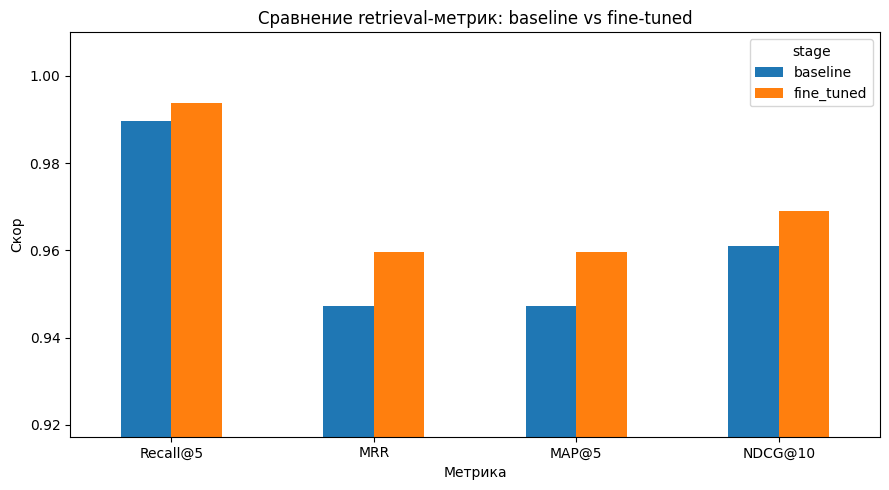

In [54]:
import pandas as pd
import matplotlib.pyplot as plt

metrics = [
    "positive_only_recall@5",
    "positive_only_mrr",
    "positive_only_map@5",
    "positive_only_ndcg@10",
]

# Оставляем только существующие колонки
metrics = [m for m in metrics if m in df.columns]

# Красивые названия
metric_labels = {
    "positive_only_recall@5": "Recall@5",
    "positive_only_mrr": "MRR",
    "positive_only_map@5": "MAP@5",
    "positive_only_ndcg@10": "NDCG@10",
}

plot_df = df.set_index("stage")[metrics].T
plot_df.index = [metric_labels.get(x, x) for x in plot_df.index]

ax = plot_df.plot(kind="bar", figsize=(9, 5), rot=0)

ax.set_ylabel("Скор")
ax.set_title("Сравнение retrieval-метрик: baseline vs fine-tuned")
ax.set_xlabel("Метрика")

# Поднимаем ограничения, чтобы разница была видна
values = plot_df.values.flatten()
values = values[~pd.isna(values)]
ax.set_ylim(min(values) - 0.03, 1.01)

plt.xticks(ticks=range(len(plot_df)), labels=plot_df.index, rotation=0)

plt.tight_layout()
plt.show()